# Los Ninos Modelling Phase

The **aim** of this notebook is to come up with a model that can predict whether a Kenyan county will flood next month using these conditions: Rain, Vegetation, Soil, Rivers, Ocean Climate, and fixed county facts.

**DATA:**
1) Train.csv - Data from 2002-2019
2) Test.csv - Data from 2020-2024
3) Model_table.csv - Combined table

**PLAN:**
Start with a baseline and a very simple Logistic Regression model, then check whether the stronger models (Random Forest & XGBoost) can actually beat them.

## Importing Libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score


## Loading the data and checking if they fit together

In [3]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
main = pd.read_csv("model_table.csv")

print(f"Train: {train.shape} | Train Years: {train.year.min()} - {train.year.max()}")
print(f"Test: {test.shape} | Test Years: {test.year.min()} - {test.year.max()}")
print(f"Main: {main.shape}")
print(f"Overlapping rows between our Train and Test values: {len(train.merge(test, on= ['pcode', 'year', 'month']))}")
print(f"Blank rows: {int(train.isna().sum().sum()) + int(test.isna().sum().sum())}")


Train: (9870, 30) | Train Years: 2002 - 2019
Test: (2820, 30) | Test Years: 2020 - 2024
Main: (12690, 30)
Overlapping rows between our Train and Test values: 0
Blank rows: 0


## Splitting into features and targets

In [4]:
not_features = ['pcode', 'year', 'month', 'county', 'flood_next_month', 'flood_this_month']
X_train = train.drop(not_features, axis= 1)
y_train = train['flood_next_month']
X_test = test.drop(not_features, axis= 1)
y_test = test['flood_next_month']

print(X_train.shape)

(9870, 24)


## Training our models

In [5]:
scores = {}

month_rate = train.groupby("month").flood_next_month.mean()
scores['calendar_baseline'] = test['month'].map(month_rate).to_numpy()

model = make_pipeline(SimpleImputer(strategy= 'median'), StandardScaler(), LogisticRegression(max_iter= 1000, class_weight= 'balanced', C= 0.3))
model.fit(X_train, y_train)
scores['logistic_regression'] = model.predict_proba(X_test)[:, 1]

print(f"Trained: {list(scores)}")

Trained: ['calendar_baseline', 'logistic_regression']


## Evaluation

In [6]:
CV = StratifiedKFold(n_splits = 5, shuffle= True, random_state= 42)
y_pred = cross_val_predict(model, X_train, y_train, cv= CV)
print(classification_report(y_train, y_pred, target_names= ['No flood', 'Flood']))

              precision    recall  f1-score   support

    No flood       0.96      0.72      0.82      8988
       Flood       0.20      0.71      0.31       882

    accuracy                           0.71      9870
   macro avg       0.58      0.71      0.56      9870
weighted avg       0.89      0.71      0.77      9870



In [7]:
rows = []

for names, i in scores.items():
  rows.append({
      "Model": names,
      "ROC-AUC" : roc_auc_score(y_test, i)
  })
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,ROC-AUC
Model,
calendar_baseline,0.762
logistic_regression,0.807


## Random Forest Classifier and XGBoost modelling

### Building and training a Random Forest model

In [8]:
rf = RandomForestClassifier(
    n_estimators = 300,
    max_depth = 8,
    min_samples_leaf = 20,
    class_weight = 'balanced',
    random_state = 42
)

rf.fit(X_train, y_train)
scores['random_forest'] = rf.predict_proba(X_test)[:, 1]
print(f"Trained: {list(scores)}")

Trained: ['calendar_baseline', 'logistic_regression', 'random_forest']


### Building and Training a XGBoost Model

In [9]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators = 300,
    max_depth = 3,
    learning_rate = 0.03,
    scale_pos_weight = ratio,
    random_state = 42
)

xgb.fit(X_train, y_train)
scores['XGB_boost'] = xgb.predict_proba(X_test)[:, 1]
print(f"Trained: {list(scores)}")

Trained: ['calendar_baseline', 'logistic_regression', 'random_forest', 'XGB_boost']


## Getting feature importances

In [10]:
importances = pd.DataFrame({
    "random_forest" : rf.feature_importances_,
    "XGB_boost" : xgb.feature_importances_
}, index= X_train.columns)

print(f"Important features for Random Forest: \n {importances.sort_values("random_forest", ascending= False).round(3).head(5)}")
print(f"Important features for XGB Boost: \n {importances.sort_values("XGB_boost", ascending= False).round(3).head(5)}")

Important features for Random Forest: 
                    random_forest  XGB_boost
dmi                        0.114      0.074
neighbour_rain             0.108      0.089
oni                        0.098      0.061
county_flood_rate          0.092      0.135
rain_mm                    0.057      0.028
Important features for XGB Boost: 
                    random_forest  XGB_boost
county_flood_rate          0.092      0.135
neighbour_rain             0.108      0.089
dmi                        0.114      0.074
month_sin                  0.054      0.074
month_cos                  0.041      0.069


### Visualizing our results

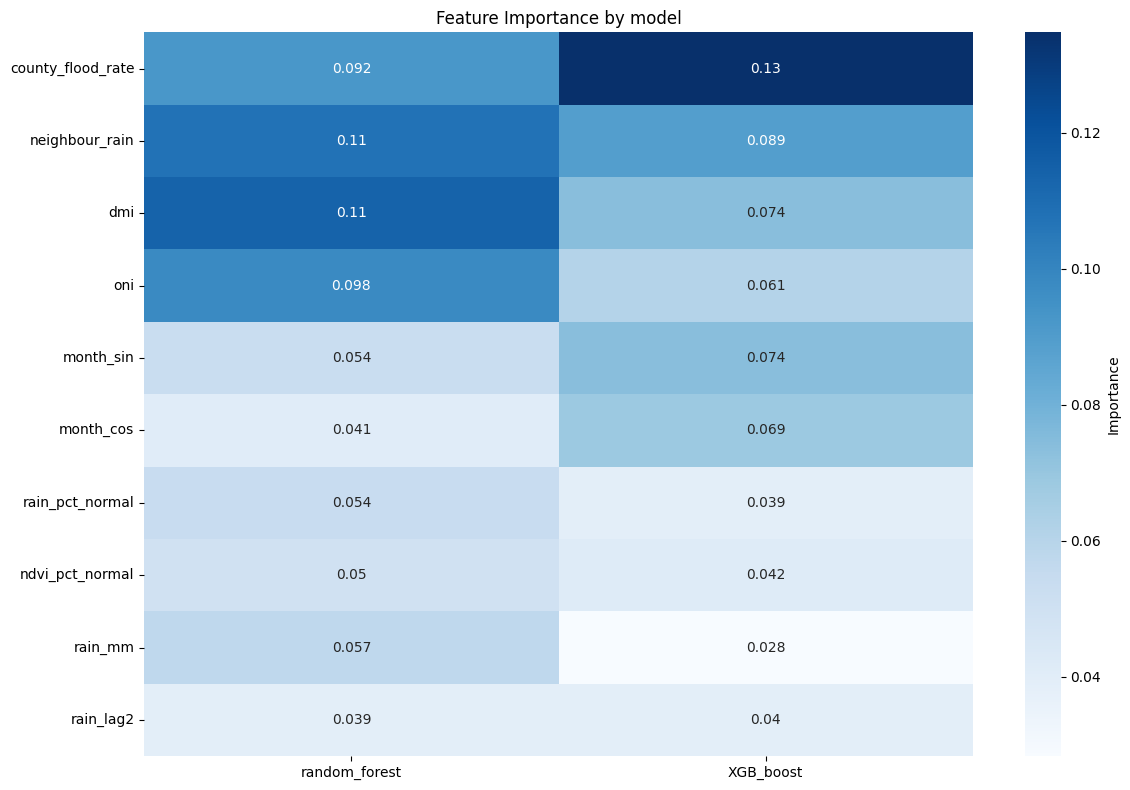

In [11]:
top_features = 10
order = importances.mean(axis= 1).sort_values(ascending= False).head(top_features).index

plt.figure(figsize=(12, 8))
sns.heatmap(importances.loc[order], annot= True, cmap= "Blues", cbar_kws= {"label": "Importance"})
plt.title("Feature Importance by model")
plt.tight_layout()
plt.show()

## Comparing our models performances

In [12]:
rows = []

for names, j in scores.items():
  rows.append({
      "Model": names,
      "ROC-AUC": roc_auc_score(y_test, j)
  })

  results = pd.DataFrame(rows).set_index("Model").round(3)

In [13]:
results

,ROC-AUC
Model,
calendar_baseline,0.762
logistic_regression,0.807
random_forest,0.798
XGB_boost,0.792
